<a href="https://colab.research.google.com/github/aiden-zhu/L02-hedonic-pricing/blob/main/L02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aiden Zhu, Noah Weinstein, Anaya Green

**Date:** 11/11/2026

4) To complete this part, I decided to create 3 different models. The first was solely the square footage of the house, the second added in factors I thought were important like the number of bedrooms and bathrooms, and the third included everything. The third/last model performed the best, and it had a test RMSE of $156,730.8 and test r^2 of 0.58. Next, the second model performed a little better than model 1. I think this is because the square footage of the house is already correlated with the number of bedrooms and bathrooms. I think if I were to do it again, I would change the second model to include other expensive features like a good view, being waterfront, or basement size.
5) Most of the numeric variables (bathrooms, stories, fireplaces) look pretty linear with the price of the house. There were a few that weren’t though, like square footage curves slightly upward, meaning a linear prediction would underpredict the price. Also for categories like a detached garage and finished attic, they are basically split into two groups with houses that either have them (many dont) and houses that do, so I don't think this model would be very accurate because of this duality. The model underpredicted some houses by a wide margin of a couple million, which represents that the sale prices are skewed.
6) Building a more complex model by adding an arcsinh transformation, squared terms, and interactions to account for nonlinear relationships between house features and sale price. The model had a training RMSE of 155,835.68 and a test RMSE of 149,745.50, with training and test R-squared values of 0.545 and 0.602. Compared to the simpler models, the complex model had the lowest test RMSE and highest test R-squared, suggesting that the added features improved its predictions.

(16814, 19) 

         sale_price  house_square_feet  attic_finished_square_feet  \
count  1.681400e+04       16814.000000                16814.000000   
mean   4.612332e+05        1879.941953                   24.945878   
std    2.360833e+05         760.419008                  102.066417   
min    2.000000e+03           1.000000                    0.000000   
25%    3.480000e+05        1320.000000                    0.000000   
50%    4.165000e+05        1774.000000                    0.000000   
75%    5.238065e+05        2352.000000                    0.000000   
max    6.130000e+06        9510.000000                 1212.000000   

       basement_square_feet  attached_garage_square_feet  \
count          16814.000000                 16814.000000   
mean             167.852861                   364.425122   
std              429.065832                   286.454018   
min                0.000000                     0.000000   
25%                0.000000                     0.00000

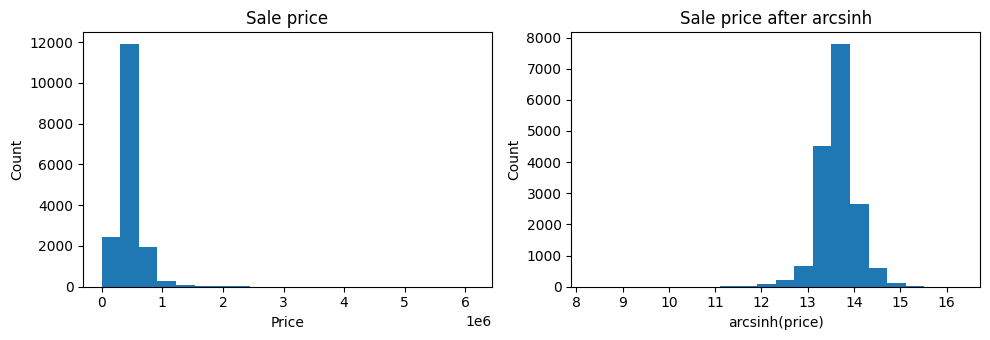

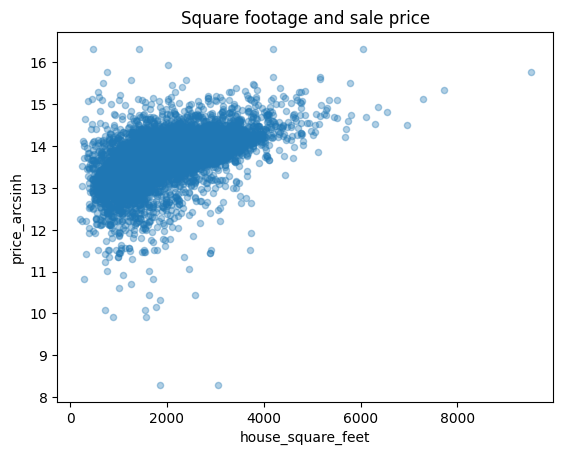

(16758, 48) 

(13406, 48) (3352, 48) 

Model 1 train R-squared: 0.277
Model 1 train RMSE: 196407.09
Model 1 test R-squared: 0.344
Model 1 test RMSE: 192167.96 

Model 2 train R-squared: 0.293
Model 2 train RMSE: 194231.36
Model 2 test R-squared: 0.369
Model 2 test RMSE: 188396.39 

Model 3 train R-squared: 0.54
Model 3 train RMSE: 156730.8
Model 3 test R-squared: 0.584
Model 3 test RMSE: 153018.36


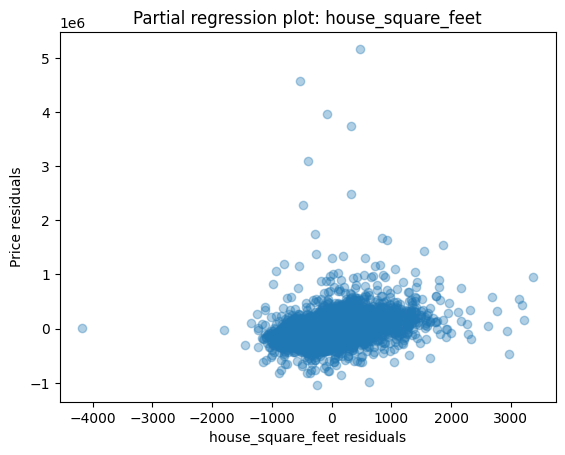

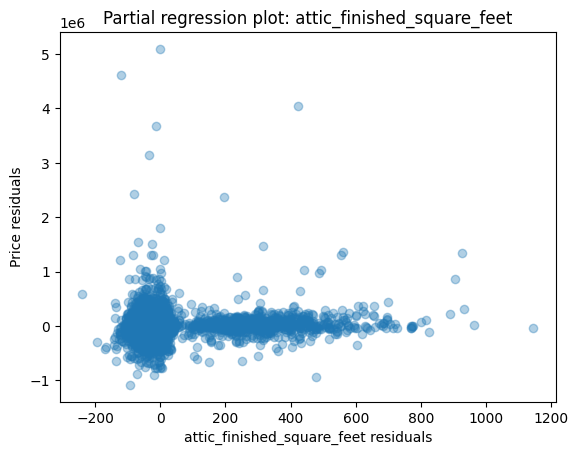

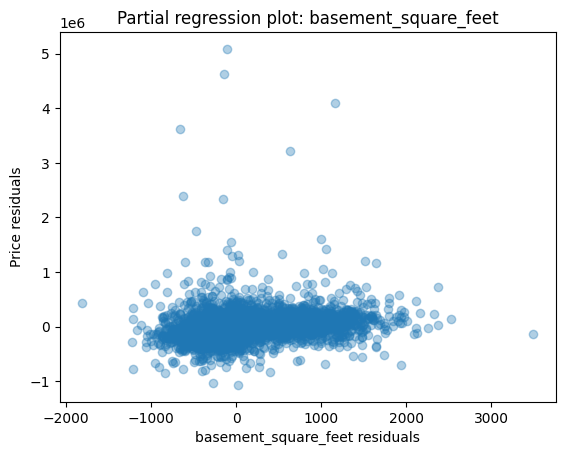

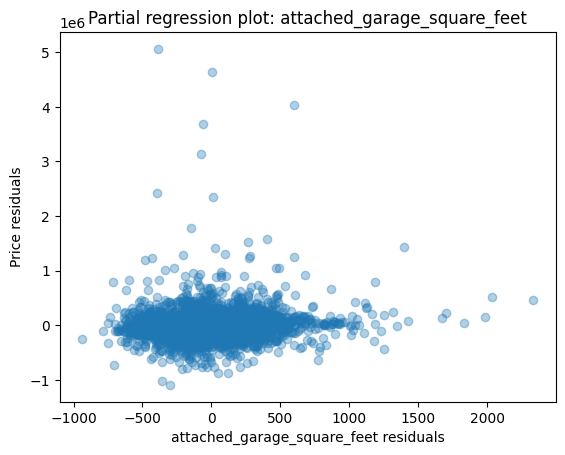

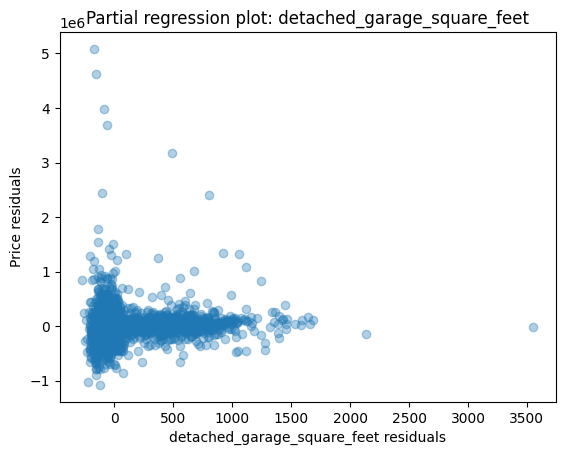

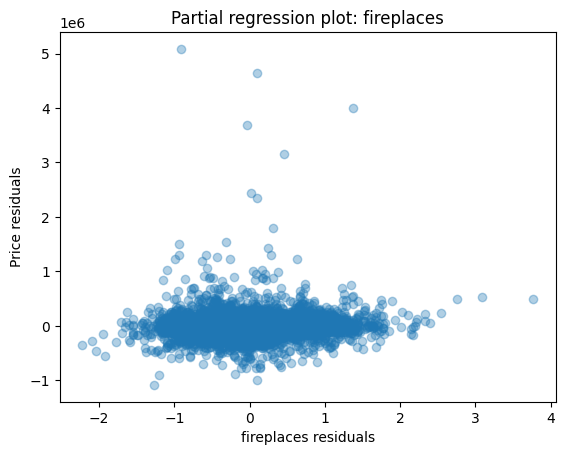

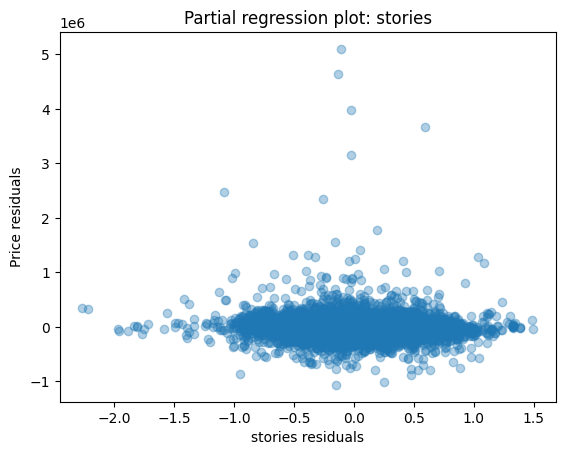

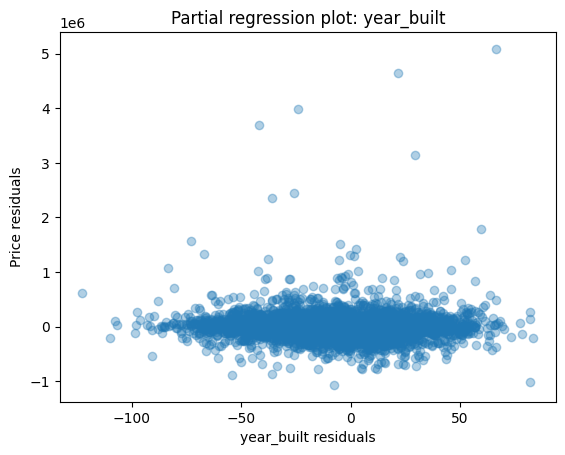

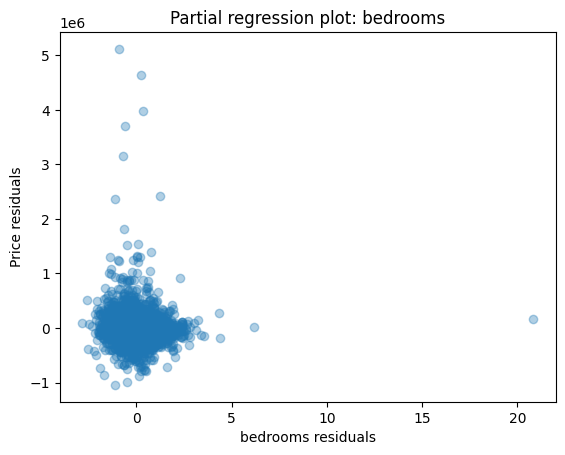

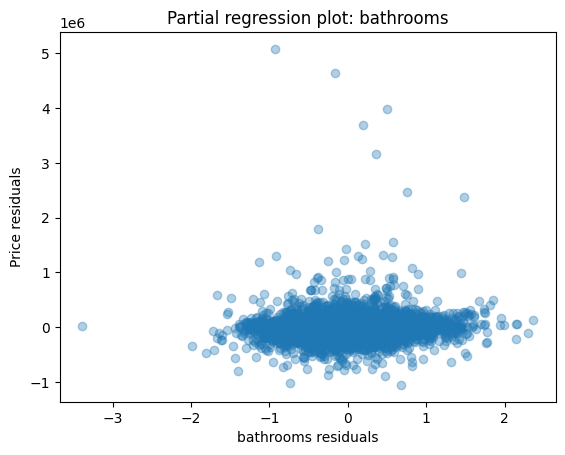

Model 6 train R-squared: 0.545
Model 6 train RMSE: 155835.68
Model 6 test R-squared: 0.602
Model 6 test RMSE: 149745.5
Model 6 train R-squared: 0.545
Model 6 train RMSE: 155835.68
Model 6 test R-squared: 0.602
Model 6 test RMSE: 149745.5

Model comparison
Model 1 test RMSE: 192167.96
Model 2 test RMSE: 188396.39
Model 3 test RMSE: 153018.36
Model 6 test RMSE: 149745.5

R-squared comparison
Model 1 test R-squared: 0.344
Model 2 test R-squared: 0.369
Model 3 test R-squared: 0.584
Model 6 test R-squared: 0.602


In [7]:
# Your Phase 1 solution to the problem goes here.
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

df = pd.read_csv("/content/pierce_county_house_sales.csv")

#Q1
print(df.shape, "\n")
print(df.describe(), "\n")
print(df.isnull().sum(), "\n")

df["bedrooms"] = df["bedrooms"].replace(0, np.nan)
df["house_square_feet"] = df["house_square_feet"].replace(1, np.nan)
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("None")
df = df.dropna()

df["price_arcsinh"] = np.arcsinh(df["sale_price"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["sale_price"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Sale price", xlabel="Price", ylabel="Count")
df["price_arcsinh"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="Sale price after arcsinh", xlabel="arcsinh(price)", ylabel="Count")
plt.tight_layout()
plt.show()

df.plot.scatter(x="house_square_feet", y="price_arcsinh", alpha=0.35)
plt.title("Square footage and sale price")
plt.show()

#Q2
features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
            "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
            "stories", "year_built", "bedrooms", "bathrooms",
            "hvac_description", "exterior", "roof_cover", "waterfront_type", "view_quality"]
y = df["sale_price"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
print(X.shape, "\n")

#Q3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100
)
print(X_train.shape, X_test.shape, "\n")

#Q4
features1 = ["house_square_feet"]
fit1 = LinearRegression().fit(X_train[features1], y_train)
residuals_train1 = y_train - fit1.predict(X_train[features1])
residuals_test1 = y_test - fit1.predict(X_test[features1])
rsq_train1 = fit1.score(X_train[features1], y_train)
rsq_test1 = fit1.score(X_test[features1], y_test)
rmse_train1 = np.sqrt(np.mean(residuals_train1**2))
rmse_test1 = np.sqrt(np.mean(residuals_test1**2))
print("Model 1 train R-squared:", round(rsq_train1, 3))
print("Model 1 train RMSE:", round(rmse_train1, 2))
print("Model 1 test R-squared:", round(rsq_test1, 3))
print("Model 1 test RMSE:", round(rmse_test1, 2), "\n")

features2 = ["house_square_feet", "bedrooms", "bathrooms"]
fit2 = LinearRegression().fit(X_train[features2], y_train)
residuals_train2 = y_train - fit2.predict(X_train[features2])
residuals_test2 = y_test - fit2.predict(X_test[features2])
rsq_train2 = fit2.score(X_train[features2], y_train)
rsq_test2 = fit2.score(X_test[features2], y_test)
rmse_train2 = np.sqrt(np.mean(residuals_train2**2))
rmse_test2 = np.sqrt(np.mean(residuals_test2**2))
print("Model 2 train R-squared:", round(rsq_train2, 3))
print("Model 2 train RMSE:", round(rmse_train2, 2))
print("Model 2 test R-squared:", round(rsq_test2, 3))
print("Model 2 test RMSE:", round(rmse_test2, 2), "\n")

fit3 = LinearRegression().fit(X_train, y_train)
residuals_train3 = y_train - fit3.predict(X_train)
residuals_test3 = y_test - fit3.predict(X_test)
rsq_train3 = fit3.score(X_train, y_train)
rsq_test3 = fit3.score(X_test, y_test)
rmse_train3 = np.sqrt(np.mean(residuals_train3**2))
rmse_test3 = np.sqrt(np.mean(residuals_test3**2))
print("Model 3 train R-squared:", round(rsq_train3, 3))
print("Model 3 train RMSE:", round(rmse_train3, 2))
print("Model 3 test R-squared:", round(rsq_test3, 3))
print("Model 3 test RMSE:", round(rmse_test3, 2))

#Q5
numeric = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
           "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
           "stories", "year_built", "bedrooms", "bathrooms"]

for var in numeric:
    others = X_train.drop(columns=var)
    r_price = y_train - LinearRegression().fit(others, y_train).predict(others)
    r_var = X_train[var] - LinearRegression().fit(others, X_train[var]).predict(others)

    plt.scatter(r_var, r_price, alpha=0.35)
    plt.xlabel(f"{var} residuals")
    plt.ylabel("Price residuals")
    plt.title(f"Partial regression plot: {var}")
    plt.show()

#Q6

  # Make copies of the training and test data so we don't alter the original datasets
X_train6 = X_train.copy()
X_test6 = X_test.copy()


# Transformation
# Apply the arcsinh transformation to house square footage in the training data
X_train6["size_ihs"] = np.arcsinh(X_train6["house_square_feet"])

# Apply the same transformation to house square footage in the test data
X_test6["size_ihs"] = np.arcsinh(X_test6["house_square_feet"])



# Interaction features
# Selected three variables we want to create polynomial and interaction terms from
small_train = X_train6[["house_square_feet", "bedrooms", "bathrooms"]]

# Do the same for test data
small_test = X_test6[["house_square_feet", "bedrooms", "bathrooms"]]

# Create an expander that generates squared terms and interactions up to degree 2
# include_bias=False prevents adding an unnecessary column of 1's
expander = PolynomialFeatures(degree=2, include_bias=False)

# Create the polynomial and interaction features for the training data
expanded_train = expander.fit_transform(small_train)

# Apply the same feature expansion to the test data
expanded_test = expander.transform(small_test)

# Convert the expanded training features into a DataFrame
expanded_train = pd.DataFrame(
    expanded_train, # The new feature values
    columns=expander.get_feature_names_out(), # Names of the new features
    index=X_train6.index # Keep the original training row indexes
)

# Convert the expanded test features into a DataFrame
expanded_test = pd.DataFrame(
    expanded_test, # The new feature values
    columns=expander.get_feature_names_out(), # Use the same feature names
    index=X_test6.index # Keep the original test row indexes
)

# Get only the new squared and interaction terms
#skips the first three columns, which are the original variables
new_features = expander.get_feature_names_out()[3:]

# Add the new polynomial and interaction terms to the original training features
X_train6 = pd.concat([X_train6, expanded_train[new_features]], axis=1)

# Add the same new features to the original test features
X_test6 = pd.concat([X_test6, expanded_test[new_features]], axis=1)

#fit complex model or calculate its RMSE and R^2 .
fit6 = LinearRegression().fit(X_train6, y_train)
residuals_train6 = y_train - fit6.predict(X_train6)
residuals_test6 = y_test - fit6.predict(X_test6)
rsq_train6 = fit6.score(X_train6, y_train)
rsq_test6 = fit6.score(X_test6, y_test)
rmse_train6 = np.sqrt(np.mean(residuals_train6**2))
rmse_test6 = np.sqrt(np.mean(residuals_test6**2))
print("Model 6 train R-squared:", round(rsq_train6, 3))
print("Model 6 train RMSE:", round(rmse_train6, 2))
print("Model 6 test R-squared:", round(rsq_test6, 3))
print("Model 6 test RMSE:", round(rmse_test6, 2))




# Comparing
# Print the training and test results
print("Model 6 train R-squared:", round(rsq_train6, 3))
print("Model 6 train RMSE:", round(rmse_train6, 2))
print("Model 6 test R-squared:", round(rsq_test6, 3))
print("Model 6 test RMSE:", round(rmse_test6, 2))

# Compare the test RMSE values from the other four models
print("\nModel comparison")
print("Model 1 test RMSE:", round(rmse_test1, 2))
print("Model 2 test RMSE:", round(rmse_test2, 2))
print("Model 3 test RMSE:", round(rmse_test3, 2))
print("Model 6 test RMSE:", round(rmse_test6, 2))

# Compare the test R^2 values from all four models
print("\nR-squared comparison")
print("Model 1 test R-squared:", round(rsq_test1, 3))
print("Model 2 test R-squared:", round(rsq_test2, 3))
print("Model 3 test R-squared:", round(rsq_test3, 3))
print("Model 6 test R-squared:", round(rsq_test6, 3))




## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]